#Load the dataset

I’m using the supplied insurance dataset to predict charges. I’ll explore the data, prepare the features and compare regression models using the same training and test split.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("insurance.csv")
df.head()

Saving insurance.csv to insurance.csv


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


#Inspect the data

I’ll check the size, data types, missing values and duplicates before changing anything.

In [2]:
print("Shape:", df.shape)
df.info()

print("\nSummary statistics:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Summary statistics:
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.6937

The dataset has 1,338 rows and seven columns. There are no missing values and one fully duplicated row. Charges range from about 1,122 to 63,770, so I’ll look at their distribution before modelling.

#Remove the duplicate

I’m removing the repeated row so the same record is not counted twice. I’m keeping the high charges because a large value alone does not prove there is an error.

In [3]:
df_clean = df.drop_duplicates().copy()

print("Cleaned shape:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

Cleaned shape: (1337, 7)
Remaining duplicates: 0


#Explore charges

I’ll use a histogram and skewness to check how charges are distributed.

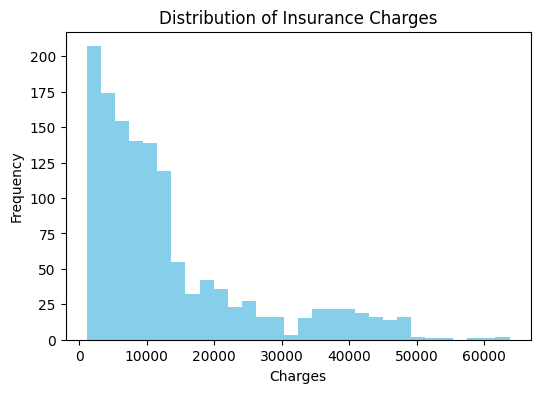

Mean charges: 13279.121486655948
Median charges: 9386.1613
Skewness: 1.5153909108403483


In [4]:
plt.figure(figsize=(6, 4))
plt.hist(df_clean["charges"], bins=30, color="skyblue")
plt.title("Distribution of Insurance Charges")
plt.xlabel("Charges")
plt.ylabel("Frequency")
plt.show()

print("Mean charges:", df_clean["charges"].mean())
print("Median charges:", df_clean["charges"].median())
print("Skewness:", df_clean["charges"].skew())

Charges are positively skewed, with a smaller number of expensive records stretching the distribution to the right. The skewness is approximately 1.52. I’ll also try a log-transformed target to see whether it improves predictions.

#Explore smoker status, age and BMI

I’ll compare charges by smoker status, then look at their relationships with age and BMI.

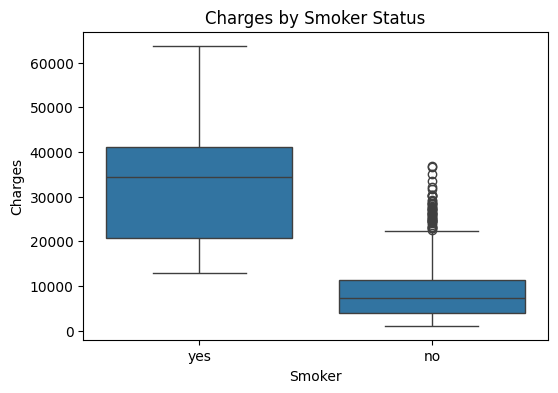

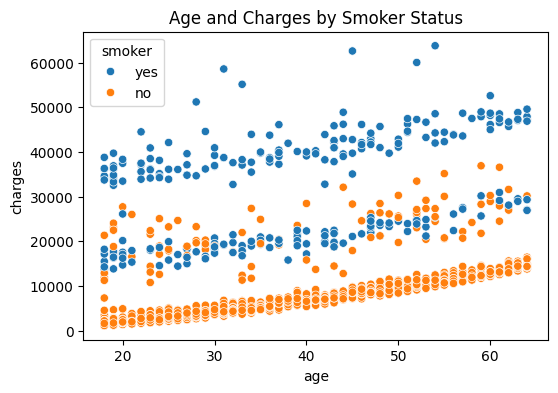

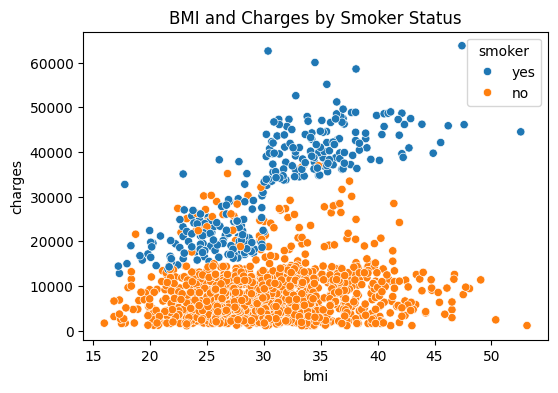

             charges                   
                mean       median count
smoker                                 
no       8440.660307   7345.72660  1063
yes     32050.231832  34456.34845   274


In [5]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="smoker", y="charges", data=df_clean)
plt.title("Charges by Smoker Status")
plt.xlabel("Smoker")
plt.ylabel("Charges")
plt.show()

plt.figure(figsize=(6, 4))
sns.scatterplot(
    x="age", y="charges", hue="smoker", data=df_clean
)
plt.title("Age and Charges by Smoker Status")
plt.show()

plt.figure(figsize=(6, 4))
sns.scatterplot(
    x="bmi", y="charges", hue="smoker", data=df_clean
)
plt.title("BMI and Charges by Smoker Status")
plt.show()

print(
    df_clean.groupby("smoker").agg({
        "charges": ["mean", "median", "count"]
    })
)

Smokers have much higher charges in this dataset. Their median charge is approximately 34,456, compared with 7,346 for non-smokers. The scatter plots also suggest that the relationships with age and BMI differ between the two groups.

#Encode categorical columns

I’m one-hot encoding sex, smoker status and region. This converts the categories into numerical indicators without giving them an artificial order. I’m using drop_first=True, as shown in Lab 10.

In [6]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=["sex", "smoker", "region"],
    drop_first=True
)

print(df_encoded.columns.tolist())
df_encoded.head()

['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


#Create an interaction feature

I’m creating smoker_bmi by multiplying BMI by the smoker indicator. It equals BMI for smokers and zero for non-smokers. This lets the regression model represent a different relationship between BMI and charges for smokers.

In [7]:
df_encoded["smoker_bmi"] = (
    df_encoded["bmi"] * df_encoded["smoker_yes"]
)

print(df_encoded[["bmi", "smoker_yes", "smoker_bmi"]].head())

print("\nMedian charges by smoker status:")
print(df_clean.groupby("smoker").agg({"charges": "median"}))

      bmi  smoker_yes  smoker_bmi
0  27.900        True        27.9
1  33.770       False         0.0
2  33.000       False         0.0
3  22.705       False         0.0
4  28.880       False         0.0

Median charges by smoker status:
            charges
smoker             
no       7345.72660
yes     34456.34845


#Create one consistent split

All models will use the same training and test rows. I’m keeping the target in its original units for the main comparisons. I won’t scale these inputs because ordinary linear regression does not require equal feature scales, although that means the raw coefficients cannot be ranked directly as feature importance.

In [8]:
features = [
    "age",
    "bmi",
    "children",
    "sex_male",
    "smoker_yes",
    "region_northwest",
    "region_southeast",
    "region_southwest",
    "smoker_bmi"
]

X = df_encoded[features]
y = df_encoded["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])

Training rows: 1069
Test rows: 268


#Simple linear regression

I’m using smoker status as the single input because the exploration showed a clear difference in charges between smokers and non-smokers.

In [9]:
model_simple = LinearRegression()

model_simple.fit(X_train[["smoker_yes"]], y_train)

pred_simple = model_simple.predict(X_test[["smoker_yes"]])

#Multiple linear regression

This model uses all nine prepared features, including the smoker–BMI interaction.

In [10]:
model_multi = LinearRegression()
model_multi.fit(X_train, y_train)

pred_multi = model_multi.predict(X_test)

#Polynomial regression

I’m applying degree-2 polynomial features to the prepared inputs. This uses the same method as Lab 7 and allows squared terms and interactions between inputs. I’ll check whether the extra flexibility actually improves test performance.

In [11]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)

pred_poly = model_poly.predict(X_test_poly)

#Trying a log-transformed target

I’ll also train multiple regression using log-transformed charges. The transformation reduces skewness, but that does not automatically mean it will predict costs better. I’ll convert the predictions back before comparing the models.

In [12]:
charges_log = np.log1p(df_encoded["charges"])

print("Original skewness:", df_encoded["charges"].skew())
print("Log-transformed skewness:", charges_log.skew())

model_log = LinearRegression()
model_log.fit(X_train, np.log1p(y_train))

pred_log_transformed = model_log.predict(X_test)

# Inverse of log1p: converts predictions back to cost units.
pred_log = np.expm1(pred_log_transformed)

Original skewness: 1.5153909108403483
Log-transformed skewness: -0.08955835073325998


#Compare all four models

I’ll compare every model using R², MAE, MSE and RMSE. All metrics below use charges in their original units.

In [13]:
from sklearn.metrics import mean_absolute_error

def evaluate_model(actual, predicted):
    return {
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mean_squared_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

comparison = pd.DataFrame({
    "Simple Linear": evaluate_model(y_test, pred_simple),
    "Multiple Linear": evaluate_model(y_test, pred_multi),
    "Polynomial": evaluate_model(y_test, pred_poly),
    "Multiple Linear - Log Target": evaluate_model(y_test, pred_log)
})

print(comparison)

      Simple Linear  Multiple Linear    Polynomial  \
R2     6.732663e-01     8.862046e-01  8.820300e-01   
MAE    5.830636e+03     2.828974e+03  2.847401e+03   
MSE    6.003930e+07     2.091060e+07  2.167770e+07   
RMSE   7.748503e+03     4.572811e+03  4.655931e+03   

      Multiple Linear - Log Target  
R2                    5.882261e-01  
MAE                   4.187417e+03  
MSE                   7.566595e+07  
RMSE                  8.698618e+03  


I’m selecting multiple linear regression. It has the highest test R² and the lowest MAE and RMSE among the models tested, while being simpler than the polynomial model. The log transformation reduced skewness but made predictions worse on the original cost scale, so I’m not using it in the final model.

#Five-fold cross-validation

I’ll check the selected model using five-fold cross-validation on the training data. This gives another view of performance without including the held-out test rows.

In [14]:
cv_scores = cross_val_score(
    model_multi,
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("R2 for each fold:", cv_scores)
print("Average R2:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

R2 for each fold: [0.77712948 0.83520327 0.8184272  0.82405652 0.8541451 ]
Average R2: 0.8217923127152581
Standard deviation: 0.025447103725228435


The average cross-validation R² is approximately 0.822. This is lower than the held-out test result, showing that the performance estimate varies depending on which records are used for evaluation.

#Examine coefficients

I’ll inspect the coefficients to understand how the selected model uses its inputs. Their units differ, so the largest number is not automatically the most important feature.

In [15]:
print("Intercept:", model_multi.intercept_)

for feature, coefficient in zip(features, model_multi.coef_):
    print(f"{feature}: {coefficient:.4f}")

Intercept: -1836.0833059618308
age: 259.0440
bmi: 12.4920
children: 570.0416
sex_male: -647.3660
smoker_yes: -21687.8301
region_northwest: -438.1614
region_southeast: -895.6698
region_southwest: -884.5646
smoker_bmi: 1476.6039


Age has a positive coefficient of approximately 259 per year, holding the other inputs fixed. The smoker–BMI interaction is also positive, allowing BMI to have a stronger relationship with predicted charges for smokers. The smoker coefficient is negative on its own, but it must be interpreted together with the interaction: the model’s smoker difference is approximately −21,688 plus 1,477 multiplied by BMI. It would therefore be wrong to conclude that smoking lowers predicted charges from the smoker coefficient alone.

#Save the final model

I’ll save the trained model and its feature names so I can load it later without retraining.

In [16]:
import joblib

saved_model = {
    "model": model_multi,
    "features": features
}

joblib.dump(
    saved_model,
    "Assignment2_Maryam_Chaudhry.joblib"
)

print("Model saved.")

Model saved.


#Create the prediction function

This function loads the saved model and prepares one person’s details using the same indicator columns and interaction as training. Inputs should use the dataset’s labels: male or female, yes or no, and the four region names.

In [17]:
def predict_insurance_cost(age, sex, bmi, children, smoker, region):
    saved = joblib.load("Assignment2_Maryam_Chaudhry.joblib")
    loaded_model = saved["model"]

    person = pd.DataFrame({
        "age": [age],
        "bmi": [bmi],
        "children": [children],
        "sex_male": [sex == "male"],
        "smoker_yes": [smoker == "yes"],
        "region_northwest": [region == "northwest"],
        "region_southeast": [region == "southeast"],
        "region_southwest": [region == "southwest"],
        "smoker_bmi": [bmi * (smoker == "yes")]
    })

    prediction = loaded_model.predict(person[saved["features"]])

    return prediction[0]

#Test two example inputs

I’ll test the function with two hypothetical profiles. These demonstrate that the saved model works; they are not evidence of prediction accuracy or real insurance quotes.

In [18]:
example_1 = predict_insurance_cost(
    age=30,
    sex="female",
    bmi=28,
    children=1,
    smoker="no",
    region="northeast"
)

example_2 = predict_insurance_cost(
    age=45,
    sex="male",
    bmi=32,
    children=2,
    smoker="yes",
    region="southeast"
)

print(f"Example 1 predicted cost: {example_1:.2f}")
print(f"Example 2 predicted cost: {example_2:.2f}")

Example 1 predicted cost: 6855.05
Example 2 predicted cost: 35381.18


The multiple linear regression model performed best among the approaches I tested. The smoker–BMI interaction helped represent a relationship that a single smoker indicator could not capture on its own. The results are estimates from this dataset, and the model does not include every factor that could affect insurance charges. I would check its performance on additional data before using it outside this assignment.